## Purpose of This Notebook

This notebook serves to create the Corrected views.

We create some interim views, before creating the final outputs, new views:

- `ExperimentCBsCorrected` (the `ExperimentCBs` table with additions)
- `TrialCBsCorrected` (the `TrialCBs` table with corrections/additions)
- `ResponseCBsCorrected` (the `ResponseCBs` table with corrections/additions)
- `EventCBsCorrected` (the `EventCBs` table with corrections/additions)

These `Corrected` versions of the data are the views that should be used for all of the analysis.

Given that only partial (key) data was captured in the Corrections workbook it is not possible to populate all
values within these new views. For example details like Start and Finish times are not available, just response times. 
In these case all such values are represented as `NULL` in the views.


In [1]:
# | echo: false

# from datetime import datetime
# from typing import List, Optional
# from pathlib import Path

# import duckdb
# import pandas as pd
# from loguru import logger

from horse_logic.project import Project

### Setup project & directories


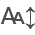

INFO     | Data directory: /Users/mjboothaus/code/github/databooth/horse-logic/data
INFO     | Data directory purpose: Parent directory for raw and processed data
INFO     | Sql directory: /Users/mjboothaus/code/github/databooth/horse-logic/sql
INFO     | Sql directory purpose: Store SQL scripts
INFO     | Output directory: /Users/mjboothaus/code/github/databooth/horse-logic/notebooks/results/CB
INFO     | Output directory purpose: Store output files and results by experiment type
INFO     | Logfiles directory: /Users/mjboothaus/code/github/databooth/horse-logic/data/results/zips/cb_data
INFO     | Logfiles directory purpose: Store for the raw log files
INFO     | Notebooks directory: /Users/mjboothaus/code/github/databooth/horse-logic/notebooks
INFO     | Notebooks directory purpose: Jupyter notebooks for performing analysis
INFO     | Database file path: /Users/mjboothaus/code/github/databooth/horse-logic/data/Experiments_CB_2023_Q4.ddb
INFO     | Database purpose: Main project datab

In [2]:
# | echo: false

project = Project(experiment_type="CB", table_page_length=25, delete_existing_db=False)
con = project.get_db_connection()

# project.drop_all_views()
project.drop_all_tables_except_defaults()

EXPERIMENT_TYPE = project.experiment_type

DATA_DIR = project.data_dir
LOGFILES_DIR = project.logfiles_dir
NOTEBOOK_DIR = project.notebooks_dir
OUTPUT_DIR = project.output_dir

### Create / compare Corrected views of `ExperimentCBs`, `TrialCBs`, `ResponseCBs` and `EventCBs` tables

### `ExperimentCBsCorrected` table

- Purpose: Combines existing experiments with new experiments from corrections.
- Approach: Uses a UNION ALL to combine existing and new experiments.
- Structure: View that includes all original experiments and adds new ones from the Corrections table.
- Features: Assigns new ExperimentIDs to added experiments and includes a `DataSource` column.

Note:

- At this stage there is only one new experiment (Yoshi with no logfile).

#### `AddExperiments` view

First we determine which Experiments need to be added from the `Corrections` table.

In [3]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW AddExperiments AS
WITH FirstComments AS (
    SELECT 
        LogFilename,
        FIRST_VALUE(Comment) OVER (
            PARTITION BY LogFilename 
            ORDER BY TrialNumber
        ) AS FirstComment
    FROM Corrections
)
SELECT DISTINCT 
    c.Cohort,
    c.ExperimentDate,
    c.SessionType,
    c.SubjectName,
    c.LogFilename,
    fc.FirstComment AS Comment,
    'Corrections xlsx: ADD' AS DataSource
FROM Corrections c
LEFT JOIN ExperimentCBs e ON c.LogFilename = e.LogFileName
LEFT JOIN FirstComments fc ON c.LogFilename = fc.LogFilename
WHERE e.LogFileName IS NULL;
"""

con.sql(sql)

In [4]:
# | echo: false

project.view_and_export_table("AddExperiments")

INFO     | Exported table: AddExperiments. 1 total rows exported to XLSX across 1 sheets.


[results/CB/AddExperiments.xlsx](results/CB/AddExperiments.xlsx)

### Table: AddExperiments

Cohort ExperimentDate SessionType SubjectName  \
0    CSU     2023-11-17        CBF3       yoshi   

                                      LogFilename  \
0  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi   

                                             Comment             DataSource  
0  Ran CBR1 but should be CBF3- so manually check...  Corrections xlsx: ADD

#### Low Cardinality columns for AddExperiments

column_name  distinct_count  \
0          Cohort               1   
1  ExperimentDate               1   
2     SessionType               1   
3     SubjectName               1   
4     LogFilename               1   
5         Comment               1   
6      DataSource               1   

                                        unique_values_with_counts  
0                                                         CSU (1)  
1                                                  2023-11-17 (1)  
2                                                        CBF3 (1)  
3                                                       yoshi (1)  
4              NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi (1)  
5  Ran CBR1 but should be CBF3- so manually check all timings (1)  
6                                       Corrections xlsx: ADD (1)

In [5]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW ReformattedAddExperiments AS
SELECT 
    ROW_NUMBER() OVER (ORDER BY a.LogFilename) + COALESCE((SELECT MAX(ExperimentID) FROM ExperimentCBs), 0) AS ExperimentID,
    a.Cohort,
    a.SubjectName,
    sb.SubjectNumber,  -- Look up SubjectNumber from SubjectCBs
    NULL AS SessionNumber,   -- Assume unavailable from Corrections info (and/or can't be inferred)
    a.SessionType,   
    NULL AS ExperimentType,  -- Assume unavailable from Corrections info (and/or can't be inferred)
    sb.Direction,      -- Look up Direction from SubjectCBs
    a.Comment,
    CAST(a.ExperimentDate AS TIMESTAMP) AS DateTime,
    a.LogFilename,
    NULL::JSON AS Parameters,  -- Assuming Parameters is JSON and initialising as NULL
    'AddExperiments' AS DataSource  -- Optional if you want to keep track of source
FROM 
    AddExperiments a
LEFT JOIN 
    SubjectCBs sb ON a.SubjectName = sb.SubjectName;  
"""

con.sql(sql)

In [6]:
# | echo: false

project.view_and_export_table("ReformattedAddExperiments")

INFO     | Exported table: ReformattedAddExperiments. 1 total rows exported to XLSX across 1 sheets.


[results/CB/ReformattedAddExperiments.xlsx](results/CB/ReformattedAddExperiments.xlsx)

### Table: ReformattedAddExperiments

ExperimentID Cohort SubjectName  SubjectNumber  SessionNumber SessionType  \
0           184    CSU       yoshi             15            NaN        CBF3   

   ExperimentType Direction  \
0             NaN      LEFT   

                                             Comment   DateTime  \
0  Ran CBR1 but should be CBF3- so manually check... 2023-11-17   

                                      LogFilename Parameters      DataSource  
0  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       None  AddExperiments

#### Low Cardinality columns for ReformattedAddExperiments

column_name  distinct_count  \
0     ExperimentID               1   
1           Cohort               1   
2      SubjectName               1   
3    SubjectNumber               1   
4    SessionNumber               1   
5      SessionType               1   
6   ExperimentType               1   
7        Direction               1   
8          Comment               1   
9         DateTime               1   
10     LogFilename               1   
11      Parameters               1   
12      DataSource               1   

                                         unique_values_with_counts  
0                                                          184 (1)  
1                                                          CSU (1)  
2                                                        yoshi (1)  
3                                                           15 (1)  
4                                                         NULL (1)  
5                                                         CBF3 (1)  
6                                                         NULL (1)  
7                                                         LEFT (1)  
8   Ran CBR1 but should be CBF3- so manually check all timings (1)  
9                                          2023-11-17 00:00:00 (1)  
10              NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi (1)  
11                                                        NULL (1)  
12                                              AddExperiments (1)

In [7]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW ExperimentCBsCorrected AS
SELECT 
    *,
    'ExperimentCBs' AS DataSource
FROM 
    ExperimentCBs

UNION ALL

SELECT 
    * EXCLUDE (DataSource),
    CONCAT(DataSource, ' -> ReformattedAddExperiments') AS DataSource
FROM 
    ReformattedAddExperiments
ORDER BY 
    ExperimentID;
"""

con.sql(sql)

In [8]:
# | echo: false

project.view_and_export_sql(
    "SELECT * EXCLUDE Parameters FROM ExperimentCBsCorrected",
    "ExperimentCBsCorrected without Parameters",
)

INFO     | Exported query results: ExperimentCBsCorrected without Parameters. 184 total rows exported to XLSX across 1 sheets.


[results/CB/ExperimentCBsCorrected without Parameters.xlsx](results/CB/ExperimentCBsCorrected%20without%20Parameters.xlsx)

### Query Results: ExperimentCBsCorrected without Parameters

ExperimentID Cohort SubjectName  SubjectNumber  SessionNumber  \
0               1     HD        atom              1            2.0   
1               2     HD         ash              2            2.0   
2               3     HD      mowgli              3            1.0   
3               4     HD       teddy              4            1.0   
4               5     HD       dodge              5            1.0   
..            ...    ...         ...            ...            ...   
179           180    CSU       yoshi             15           11.0   
180           181    CSU       dusty             18           10.0   
181           182    CSU       dusty             18           11.0   
182           183    CSU      clover             22            NaN   
183           184    CSU       yoshi             15            NaN   

    SessionType    ExperimentType Direction  \
0          test  Training - fixed      LEFT   
1          test  Training - fixed     RIGHT   
2          test  Training - fixed      LEFT   
3          test  Training - fixed     RIGHT   
4          test  Training - fixed      LEFT   
..          ...               ...       ...   
179        test       Test Type 1      LEFT   
180        test       Test Type 1     RIGHT   
181        test       Test Type 1     RIGHT   
182        test       Test Type 1     RIGHT   
183        CBF3              None      LEFT   

                                               Comment  \
0                                        First session   
1                                          Pos = Right   
2                                      Positive = LEFT   
3                                     Positive = RIGHT   
4                                      Positive = LEFT   
..                                                 ...   
179                                  CB T 4 after RP R   
180                                  CB T 4 after RP R   
181                                   CBT 4 after RP R   
182                                  CB T 4 after RP R   
183  Ran CBR1 but should be CBF3- so manually check...   

                      DateTime  \
0   2023-10-06 12:49:44.174442   
1   2023-10-06 13:21:53.770221   
2   2023-10-06 14:14:41.653330   
3   2023-10-06 14:48:40.419276   
4   2023-10-06 15:37:08.619329   
..                         ...   
179 2023-11-17 03:22:54.109367   
180 2023-11-17 04:05:53.213724   
181 2023-11-17 04:39:51.602365   
182 2023-11-17 05:22:49.445377   
183 2023-11-17 00:00:00.000000   

                                           LogFileName  \
0    Experiment_2023-10-06T12:49:44.174442_atom_2_T...   
1    Experiment_2023-10-06T13:21:53.770221_ash_2_Tr...   
2    Experiment_2023-10-06T14:14:41.653330_mowgli_1...   
3    Experiment_2023-10-06T14:48:40.419276_teddy_1_...   
4    Experiment_2023-10-06T15:37:08.619329_dodge_1_...   
..                                                 ...   
179  Experiment_2023-11-17T03:22:54.109367_yoshi_11...   
180  Experiment_2023-11-17T04:05:53.213724_dusty_10...   
181  Experiment_2023-11-17T04:39:51.602365_dusty_11...   
182  Experiment_2023-11-17T05:22:49.445377_clover_n...   
183     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi   

                                      DataSource  
0                                  ExperimentCBs  
1                                  ExperimentCBs  
2                                  ExperimentCBs  
3                                  ExperimentCBs  
4                                  ExperimentCBs  
..                                           ...  
179                                ExperimentCBs  
180                                ExperimentCBs  
181                                ExperimentCBs  
182                                ExperimentCBs  
183  AddExperiments -> ReformattedAddExperiments  

[184 rows x 12 columns]

In [9]:
# | echo: false

con.sql("SELECT * FROM ExperimentCBsCorrected WHERE LogFilename LIKE '%NO_LOGFILE_AVAILABLE_%'").df()

ExperimentID Cohort SubjectName  SubjectNumber  SessionNumber SessionType  \
0           184    CSU       yoshi             15            NaN        CBF3   

  ExperimentType Direction                                            Comment  \
0           None      LEFT  Ran CBR1 but should be CBF3- so manually check...   

    DateTime                                     LogFileName Parameters  \
0 2023-11-17  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       None   

                                    DataSource  
0  AddExperiments -> ReformattedAddExperiments

**Mon_11Nov_Item1: RESOLUTION REQUIRED: `ExperimentCBsCorrected`**

- `SubjectNumber` and `Direction` have been inserted (from Subject info) for additional Yoshi experiment.
- Can any of the additional fields e.g. SessionNumber, ExperimentType (e.g. from Comment), Parameters be populated or assuming NULL?

For completeness, let's examine the additional Yoshi experiment (with no logfile) and the trial details (additions to be made) to the `TrialCBs`.

In [10]:
# | echo: false

con.sql(
    "SELECT * FROM Corrections WHERE LogFilename = 'NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi'"
).df()

Cohort ExperimentDate SessionType SubjectName  TrialNumber TrialType  \
0     CSU     2023-11-17        CBF3       yoshi            1         P   
1     CSU     2023-11-17        CBF3       yoshi            2         P   
2     CSU     2023-11-17        CBF3       yoshi            3         P   
3     CSU     2023-11-17        CBF3       yoshi            4         P   
4     CSU     2023-11-17        CBF3       yoshi            5         P   
5     CSU     2023-11-17        CBF3       yoshi            6         P   
6     CSU     2023-11-17        CBF3       yoshi            7         P   
7     CSU     2023-11-17        CBF3       yoshi            8         P   
8     CSU     2023-11-17        CBF3       yoshi            9         P   
9     CSU     2023-11-17        CBF3       yoshi           10         P   
10    CSU     2023-11-17        CBF3       yoshi           11        N    
11    CSU     2023-11-17        CBF3       yoshi           12        N    
12    CSU     2023-11-17        CBF3       yoshi           13        N    
13    CSU     2023-11-17        CBF3       yoshi           14        N    
14    CSU     2023-11-17        CBF3       yoshi           15        N    
15    CSU     2023-11-17        CBF3       yoshi           16        N    
16    CSU     2023-11-17        CBF3       yoshi           17        N    
17    CSU     2023-11-17        CBF3       yoshi           18        N    
18    CSU     2023-11-17        CBF3       yoshi           19        N    
19    CSU     2023-11-17        CBF3       yoshi           20        N    

    ResponseTime ResponseType  \
0          11.13           GO   
1          12.67           GO   
2          11.73           GO   
3          14.00           GO   
4          12.40           GO   
5          12.94           GO   
6          12.37           GO   
7          26.70           GO   
8          16.89           GO   
9          11.99           GO   
10         30.00         NOGO   
11         30.00         NOGO   
12         30.00         NOGO   
13         30.00         NOGO   
14         30.00         NOGO   
15         30.00         NOGO   
16         30.00         NOGO   
17         30.00         NOGO   
18         30.00         NOGO   
19         30.00         NOGO   

                                              Comment  \
0   Ran CBR1 but should be CBF3- so manually check...   
1                                                None   
2                                                None   
3                                                None   
4                                                None   
5                                                None   
6                                                None   
7                                                None   
8                                                None   
9                                                None   
10                                               None   
11                                               None   
12                                               None   
13                                               None   
14                                               None   
15                                               None   
16                                               None   
17                                               None   
18                                               None   
19                                               None   

                                       LogFilename           CorrectTable  \
0   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi  TrialCBs, ResponseCBs   
1   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi  TrialCBs, ResponseCBs   
2   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi  TrialCBs, ResponseCBs   
3   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi  TrialCBs, ResponseCBs   
4   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi  TrialCBs, ResponseCBs   
5   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi  TrialCBs, ResponseCBs

So there are 20 (new) trials to add as expected.

### `TrialCBsCorrected` table

- Purpose: Combines existing trials with new trials from corrections and applies corrections.
- Approach: Uses CTEs for new trials and existing trials, then combines them.
- Structure: View that includes all original trials, adds new ones, and applies corrections.
- Features: Assigns new TrialIDs to added trials and includes a `CorrectedFlag` column.

#### `AddTrials` view

In [11]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW AddTrials AS
WITH AddedTrials AS (
    SELECT 
        e.ExperimentID,
        c.TrialNumber,
        c.TrialType AS TrialSubType,
        c.ResponseType,
        CASE 
            WHEN c.TrialType = 'P' AND c.ResponseType = 'GO' THEN 'positive'
            WHEN c.TrialType = 'N' AND c.ResponseType = 'NOGO' THEN 'negative'
            ELSE NULL
        END AS CriterionType,
        NULL AS TrialStartTime,
        NULL AS TrialEndTime,
        'Added from Corrections' AS CorrectedFlag
    FROM 
        Corrections c
    JOIN 
        ExperimentCBsCorrected e ON c.LogFilename = e.LogFileName
    WHERE 
        e.DataSource LIKE '%AddExperiments%'
)
SELECT 
    ExperimentID,
    TrialNumber,
    TrialSubType,
    ResponseType,
    CriterionType,
    SUM(CASE 
        WHEN CriterionType IS NOT NULL THEN 1 
        ELSE 0 
    END) OVER (
        PARTITION BY ExperimentID, CriterionType
        ORDER BY TrialNumber
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS CriterionCount,
    TrialStartTime,
    TrialEndTime,
    CorrectedFlag
FROM AddedTrials
ORDER BY ExperimentID, TrialNumber;
"""

con.sql(sql)

In [12]:
# | echo: false

project.view_and_export_table("AddTrials")

INFO     | Exported table: AddTrials. 20 total rows exported to XLSX across 1 sheets.


[results/CB/AddTrials.xlsx](results/CB/AddTrials.xlsx)

### Table: AddTrials

ExperimentID  TrialNumber TrialSubType ResponseType CriterionType  \
0            184            1            P           GO      positive   
1            184            2            P           GO      positive   
2            184            3            P           GO      positive   
3            184            4            P           GO      positive   
4            184            5            P           GO      positive   
5            184            6            P           GO      positive   
6            184            7            P           GO      positive   
7            184            8            P           GO      positive   
8            184            9            P           GO      positive   
9            184           10            P           GO      positive   
10           184           11           N          NOGO          None   
11           184           12           N          NOGO          None   
12           184           13           N          NOGO          None   
13           184           14           N          NOGO          None   
14           184           15           N          NOGO          None   
15           184           16           N          NOGO          None   
16           184           17           N          NOGO          None   
17           184           18           N          NOGO          None   
18           184           19           N          NOGO          None   
19           184           20           N          NOGO          None   

    CriterionCount  TrialStartTime  TrialEndTime           CorrectedFlag  
0              1.0             NaN           NaN  Added from Corrections  
1              2.0             NaN           NaN  Added from Corrections  
2              3.0             NaN           NaN  Added from Corrections  
3              4.0             NaN           NaN  Added from Corrections  
4              5.0             NaN           NaN  Added from Corrections  
5              6.0             NaN           NaN  Added from Corrections  
6              7.0             NaN           NaN  Added from Corrections  
7              8.0             NaN           NaN  Added from Corrections  
8              9.0             NaN           NaN  Added from Corrections  
9             10.0             NaN           NaN  Added from Corrections  
10             0.0             NaN           NaN  Added from Corrections  
11             0.0             NaN           NaN  Added from Corrections  
12             0.0             NaN           NaN  Added from Corrections  
13             0.0             NaN           NaN  Added from Corrections  
14             0.0             NaN           NaN  Added from Corrections  
15             0.0             NaN           NaN  Added from Corrections  
16             0.0             NaN           NaN  Added from Corrections  
17             0.0             NaN           NaN  Added from Corrections  
18             0.0             NaN           NaN  Added from Corrections  
19             0.0             NaN           NaN  Added from Corrections

#### Low Cardinality columns for AddTrials

column_name  distinct_count    unique_values_with_counts
0    ExperimentID               1                     184 (20)
1  TrialStartTime               1                    NULL (20)
2    TrialEndTime               1                    NULL (20)
3   CorrectedFlag               1  Added from Corrections (20)
4    TrialSubType               2              N  (10), P (10)
5    ResponseType               2           GO (10), NOGO (10)
6   CriterionType               2     NULL (10), positive (10)

In [13]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW CorrectTrials AS
SELECT 
    t.TrialID, 
    t.ExperimentID, 
    t.TrialNumber, 
    t.TrialSubType, 
    COALESCE(cs.ValueToCorrect, t.ResponseType) AS ResponseType,
    t.CriterionType, 
    t.CriterionCount, 
    t.TrialStartTime, 
    t.TrialEndTime,
    CASE 
        WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != t.ResponseType THEN 'Corrected: ResponseType'
        ELSE 'Original: not a correction' 
    END AS CorrectedFlag
FROM TrialCBs t
LEFT JOIN ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
LEFT JOIN CorrectionsSplit cs ON e.LogFileName = cs.LogFilename 
    AND t.TrialNumber = cs.TrialNumber 
    AND cs.TableToCorrect = 'TrialCBs'
    AND cs.FieldToCorrect = 'ResponseType'
"""

con.sql(sql)

In [14]:
# | echo: false

project.view_and_export_table("CorrectTrials")

INFO     | Exported table: CorrectTrials. 3173 total rows exported to XLSX across 1 sheets.


[results/CB/CorrectTrials.xlsx](results/CB/CorrectTrials.xlsx)

### Table: CorrectTrials

TrialID  ExperimentID  TrialNumber TrialSubType ResponseType  \
0         206            12            6            P           GO   
1         281            16            1            P           GO   
2         288            16            8            P           GO   
3         345            19            5            P           GO   
4         384            21            4            P           GO   
...       ...           ...          ...          ...          ...   
3168     2629           147           11            P           GO   
3169     2630           147           12            N         NOGO   
3170     2631           147           13           NN         NOGO   
3171     2632           147           14            P           GO   
3172     2633           147           15            N         NOGO   

     CriterionType  CriterionCount             TrialStartTime  \
0         positive               5 2023-10-07 10:54:51.002752   
1         positive               1 2023-10-07 14:49:21.002397   
2         positive               8 2023-10-07 14:54:53.577525   
3             None               0 2023-10-07 16:59:51.184713   
4             None               0 2023-10-07 18:19:58.169716   
...            ...             ...                        ...   
3168      positive               4 2023-11-14 23:29:01.006620   
3169      negative               4 2023-11-14 23:30:08.730599   
3170          None               0 2023-11-14 23:31:35.894618   
3171      positive               5 2023-11-14 23:32:31.892706   
3172      negative               5 2023-11-14 23:33:14.156617   

                   TrialEndTime               CorrectedFlag  
0    2023-10-07 10:55:59.212652  Original: not a correction  
1    2023-10-07 14:49:35.363654  Original: not a correction  
2    2023-10-07 14:55:34.354817  Original: not a correction  
3    2023-10-07 17:01:28.195433     Corrected: ResponseType  
4    2023-10-07 18:21:51.349277     Corrected: ResponseType  
...                         ...                         ...  
3168 2023-11-14 23:29:56.722976  Original: not a correction  
3169 2023-11-14 23:31:23.890412  Original: not a correction  
3170 2023-11-14 23:32:19.887880  Original: not a correction  
3171 2023-11-14 23:33:02.152639  Original: not a correction  
3172 2023-11-14 23:34:20.111506  Original: not a correction  

[3173 rows x 10 columns]

#### Low Cardinality columns for CorrectTrials

column_name  distinct_count  \
0  CorrectedFlag               2   
1   ResponseType               3   
2  CriterionType               3   
3   TrialSubType               5   

                                         unique_values_with_counts  
0  Original: not a correction (3127), Corrected: ResponseType (46)  
1                                 GO (1904), NOGO (1268), NULL (1)  
2                     positive (1350), negative (1115), NULL (708)  
3                     P (1459), N (1453), M (89), NN (86), NP (86)

So there are 50 trials (1.5% of trials) where the `ResponseType` has (actually) been corrected. Note that **only** `ResponseType` can be corrected in the Trials views, `ResponseTime` is corrected in the Response views.

In [15]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW TrialCBsCorrected AS
WITH MaxExistingTrialID AS (
    SELECT COALESCE(MAX(TrialID), 0) AS MaxID
    FROM TrialCBs
),
CombinedTrials AS (
    SELECT 
        t.TrialID,
        t.ExperimentID,
        t.TrialNumber,
        t.TrialSubType,
        COALESCE(cs.ValueToCorrect, t.ResponseType) AS ResponseType,
        t.CriterionType,
        t.CriterionCount,
        t.TrialStartTime,
        t.TrialEndTime,
        CASE 
            WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != t.ResponseType THEN 'Corrected: ResponseType'
            ELSE 'Original'
        END AS CorrectedFlag,
        0 AS IsNewTrial
    FROM TrialCBs t
    LEFT JOIN ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
    LEFT JOIN CorrectionsSplit cs ON e.LogFileName = cs.LogFilename 
        AND t.TrialNumber = cs.TrialNumber 
        AND cs.TableToCorrect = 'TrialCBs'
        AND cs.FieldToCorrect = 'ResponseType'
    
    UNION ALL
    
    SELECT 
        NULL AS TrialID,
        ExperimentID,
        TrialNumber,
        TrialSubType,
        ResponseType,
        CriterionType,
        CriterionCount,
        TrialStartTime,
        TrialEndTime,
        'Added from Corrections' AS CorrectedFlag,
        1 AS IsNewTrial
    FROM AddTrials
),
NumberedNewTrials AS (
    SELECT 
        *,
        ROW_NUMBER() OVER (ORDER BY ExperimentID, TrialNumber) AS NewTrialNum
    FROM CombinedTrials
    WHERE TrialID IS NULL
)
SELECT 
    CASE 
        WHEN ct.TrialID IS NOT NULL THEN ct.TrialID 
        ELSE m.MaxID + nnt.NewTrialNum 
    END AS TrialID,
    ct.ExperimentID,
    ct.TrialNumber,
    ct.TrialSubType,
    ct.ResponseType,
    ct.CriterionType,
    ct.CriterionCount,
    ct.TrialStartTime,
    ct.TrialEndTime,
    ct.CorrectedFlag
FROM CombinedTrials ct
LEFT JOIN NumberedNewTrials nnt ON ct.ExperimentID = nnt.ExperimentID AND ct.TrialNumber = nnt.TrialNumber
CROSS JOIN MaxExistingTrialID m
ORDER BY ct.ExperimentID, ct.TrialNumber;
"""

con.sql(sql)

In [16]:
# | echo: false

project.view_and_export_table("TrialCBs")

INFO     | Exported table: TrialCBs. 3173 total rows exported to XLSX across 1 sheets.


[results/CB/TrialCBs.xlsx](results/CB/TrialCBs.xlsx)

### Table: TrialCBs

TrialID  ExperimentID  TrialNumber ResponseType TrialSubType  \
0           1             1            1           GO            P   
1           2             1            2           GO            P   
2           3             1            3           GO            P   
3           4             1            4           GO            P   
4           5             1            5           GO            P   
...       ...           ...          ...          ...          ...   
3168     3169           183           11         NOGO            N   
3169     3170           183           12           GO            P   
3170     3171           183           13         NOGO           NN   
3171     3172           183           14           GO            P   
3172     3173           183           15         NOGO            N   

     CriterionType  CriterionCount             TrialStartTime  \
0         positive               1 2023-10-06 12:50:18.025708   
1         positive               2 2023-10-06 12:50:54.546579   
2         positive               3 2023-10-06 12:52:11.277622   
3         positive               4 2023-10-06 12:53:19.533683   
4         positive               5 2023-10-06 12:54:55.736546   
...            ...             ...                        ...   
3168      negative               5 2023-11-17 05:33:44.661577   
3169      positive               5 2023-11-17 05:34:41.033501   
3170          None               0 2023-11-17 05:35:24.235581   
3171      positive               6 2023-11-17 05:37:00.491598   
3172      negative               6 2023-11-17 05:37:43.315600   

                   TrialEndTime  
0    2023-10-06 12:50:36.543201  
1    2023-10-06 12:51:53.268573  
2    2023-10-06 12:53:01.531667  
3    2023-10-06 12:54:37.725440  
4    2023-10-06 12:55:33.610711  
...                         ...  
3168 2023-11-17 05:34:29.029880  
3169 2023-11-17 05:35:12.227923  
3170 2023-11-17 05:36:48.483987  
3171 2023-11-17 05:37:31.308051  
3172 2023-11-17 05:39:15.031031  

[3173 rows x 9 columns]

#### Low Cardinality columns for TrialCBs

column_name  distinct_count                     unique_values_with_counts
0   ResponseType               3              GO (1886), NOGO (1285), NULL (2)
1  CriterionType               3  positive (1350), negative (1115), NULL (708)
2   TrialSubType               5  P (1459), N (1453), M (89), NP (86), NN (86)

In [17]:
# | echo: false

project.view_and_export_table("TrialCBsCorrected")

INFO     | Exported table: TrialCBsCorrected. 3193 total rows exported to XLSX across 1 sheets.


[results/CB/TrialCBsCorrected.xlsx](results/CB/TrialCBsCorrected.xlsx)

### Table: TrialCBsCorrected

TrialID  ExperimentID  TrialNumber TrialSubType ResponseType  \
0           1             1            1            P           GO   
1           2             1            2            P           GO   
2           3             1            3            P           GO   
3           4             1            4            P           GO   
4           5             1            5            P           GO   
...       ...           ...          ...          ...          ...   
3188     3189           184           16           N          NOGO   
3189     3190           184           17           N          NOGO   
3190     3191           184           18           N          NOGO   
3191     3192           184           19           N          NOGO   
3192     3193           184           20           N          NOGO   

     CriterionType  CriterionCount             TrialStartTime  \
0         positive             1.0 2023-10-06 12:50:18.025708   
1         positive             2.0 2023-10-06 12:50:54.546579   
2         positive             3.0 2023-10-06 12:52:11.277622   
3         positive             4.0 2023-10-06 12:53:19.533683   
4         positive             5.0 2023-10-06 12:54:55.736546   
...            ...             ...                        ...   
3188          None             0.0                        NaT   
3189          None             0.0                        NaT   
3190          None             0.0                        NaT   
3191          None             0.0                        NaT   
3192          None             0.0                        NaT   

                   TrialEndTime           CorrectedFlag  
0    2023-10-06 12:50:36.543201                Original  
1    2023-10-06 12:51:53.268573                Original  
2    2023-10-06 12:53:01.531667                Original  
3    2023-10-06 12:54:37.725440                Original  
4    2023-10-06 12:55:33.610711                Original  
...                         ...                     ...  
3188                        NaT  Added from Corrections  
3189                        NaT  Added from Corrections  
3190                        NaT  Added from Corrections  
3191                        NaT  Added from Corrections  
3192                        NaT  Added from Corrections  

[3193 rows x 10 columns]

#### Low Cardinality columns for TrialCBsCorrected

column_name  distinct_count  \
0   ResponseType               3   
1  CriterionType               3   
2  CorrectedFlag               3   

                                                    unique_values_with_counts  
0                                            GO (1914), NOGO (1278), NULL (1)  
1                                positive (1360), negative (1115), NULL (718)  
2  Original (3127), Corrected: ResponseType (46), Added from Corrections (20)

In [18]:
# | echo: false

con.sql(
    "SELECT COUNT(*) AS nTrialsCorrected FROM TrialCBsCorrected WHERE CorrectedFlag = 'Corrected: ResponseType'"
)

┌──────────────────┐
│ nTrialsCorrected │
│      int64       │
├──────────────────┤
│               46 │
└──────────────────┘

In [19]:
# | echo: false

con.sql(
    "SELECT COUNT(*) nTrialsOriginal FROM TrialCBsCorrected WHERE CorrectedFlag != 'Corrected: ResponseType'"
)

┌─────────────────┐
│ nTrialsOriginal │
│      int64      │
├─────────────────┤
│            3147 │
└─────────────────┘

#### Diffs - `TrialCBs` vs `TrialCBsCorrected`

In [20]:
# | echo: false

sql = """
WITH TrialDifferences AS (
    SELECT 
        COALESCE(t.ExperimentID, tc.ExperimentID) AS ExperimentID,
        COALESCE(t.TrialNumber, tc.TrialNumber) AS TrialNumber,
        CASE 
            WHEN t.TrialID IS NULL THEN 'Additions (new rows)'
            WHEN tc.TrialID IS NULL THEN 'Existing (same rows)'
            WHEN t.ResponseType != tc.ResponseType THEN 'Correction to ResponseType'
            ELSE 'Existing (same rows)'
        END AS Difference
    FROM 
        TrialCBs t
    FULL OUTER JOIN 
        TrialCBsCorrected tc ON t.ExperimentID = tc.ExperimentID AND t.TrialNumber = tc.TrialNumber
)
SELECT 
    Difference,
    COUNT(*) AS Count
FROM 
    TrialDifferences
GROUP BY 
    Difference
UNION ALL
SELECT 
    'Total TrialCBs', 
    COUNT(*) 
FROM 
    TrialCBs
UNION ALL
SELECT 
    'Total TrialCBsCorrected', 
    COUNT(*) 
FROM 
    TrialCBsCorrected
ORDER BY 
    Difference;
"""

con.sql(sql)

┌────────────────────────────┬───────┐
│         Difference         │ Count │
│          varchar           │ int64 │
├────────────────────────────┼───────┤
│ Additions (new rows)       │    20 │
│ Correction to ResponseType │    46 │
│ Existing (same rows)       │  3127 │
│ Total TrialCBs             │  3173 │
│ Total TrialCBsCorrected    │  3193 │
└────────────────────────────┴───────┘

In [21]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW CorrectedResponses AS
SELECT 
    r.ResponseID, 
    r.TrialID,
    t.ExperimentID,
    t.TrialNumber,
    CASE 
        WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != '' THEN CAST(cs.ValueToCorrect AS DOUBLE)
        ELSE r.ResponseTime 
    END AS ResponseTime,
    r.EventDateTime,
    CASE 
        WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != '' AND 
             (r.ResponseTime IS NULL OR ABS(CAST(cs.ValueToCorrect AS DOUBLE) - r.ResponseTime) > 0.000001) 
            THEN 'Corrected: ResponseTime'
        WHEN cs.ValueToCorrect = '' AND r.ResponseTime IS NOT NULL THEN 'Corrected: ResponseTime to NULL'
        WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != '' AND r.ResponseTime IS NULL THEN 'Corrected: NULL to ResponseTime'
        ELSE 'Original: not a correction'
    END AS CorrectedFlag
FROM ResponseCBs r
JOIN TrialCBsCorrected t ON r.TrialID = t.TrialID
LEFT JOIN ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
LEFT JOIN CorrectionsSplit cs ON e.LogFileName = cs.LogFilename 
    AND t.TrialNumber = cs.TrialNumber 
    AND cs.TableToCorrect = 'ResponseCBs'
    AND cs.FieldToCorrect = 'ResponseTime';
"""

con.sql(sql)

In [22]:
# | echo: false

project.view_and_export_table("CorrectedResponses")

INFO     | Exported table: CorrectedResponses. 3171 total rows exported to XLSX across 1 sheets.


[results/CB/CorrectedResponses.xlsx](results/CB/CorrectedResponses.xlsx)

### Table: CorrectedResponses

ResponseID  TrialID  ExperimentID  TrialNumber  ResponseTime  \
0            206      206            12            6      8.210000   
1            281      281            16            1      8.950000   
2            288      288            16            8      7.620000   
3            345      345            19            5      9.210000   
4            384      384            21            4     10.090000   
...          ...      ...           ...          ...           ...   
3166        2630     2632           147           14     10.187400   
3167        2631     2633           147           15     30.000000   
3168        2623     2625           147            7           NaN   
3169        2628     2630           147           12     30.000000   
3170        2620     2622           147            4     11.628214   

                  EventDateTime               CorrectedFlag  
0    2023-10-07 10:55:59.212652     Corrected: ResponseTime  
1    2023-10-07 14:49:35.363654     Corrected: ResponseTime  
2    2023-10-07 14:55:34.354817     Corrected: ResponseTime  
3    2023-10-07 17:01:28.195433     Corrected: ResponseTime  
4    2023-10-07 18:21:51.349277     Corrected: ResponseTime  
...                         ...                         ...  
3166 2023-11-14 23:33:02.152639  Original: not a correction  
3167 2023-11-14 23:34:20.111506  Original: not a correction  
3168 2023-11-14 23:25:29.521827  Original: not a correction  
3169 2023-11-14 23:31:23.890412  Original: not a correction  
3170 2023-11-14 23:21:45.807538  Original: not a correction  

[3171 rows x 7 columns]

#### Low Cardinality columns for CorrectedResponses

column_name  distinct_count  \
0  CorrectedFlag               2   

                                          unique_values_with_counts  
0  Original: not a correction (2982), Corrected: ResponseTime (189)

So this suggests a total number of corrected `ReponseTime` of 144 (change of value) and one set to NULL (8% of the overall values).

### `ResponseCBsCorrected` table

- Purpose: Combines existing responses with new responses from corrections and applies corrections.
- Approach: Similar to `TrialCBsCorrected`, uses CTEs for new and existing responses.
- Structure: View that includes all original responses, adds new ones, and applies corrections.
- Features: Assigns new `ResponseID`s to added responses and includes a `CorrectedFlag` column.

In [23]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW ResponseCBsCorrected AS
WITH NewResponses AS (
    SELECT 
        NULL AS ResponseID, 
        t.TrialID,
        CAST(c.ResponseTime AS DOUBLE) AS ResponseTime,
        NULL AS EventDateTime,
        'Added from Corrections' AS CorrectedFlag
    FROM TrialCBsCorrected t
    JOIN ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
    JOIN Corrections c ON e.LogFileName = c.LogFilename AND t.TrialNumber = c.TrialNumber
    WHERE e.DataSource LIKE '%AddExperiments%'
),
ExistingResponses AS (
    SELECT 
        r.ResponseID, 
        r.TrialID,
        CASE 
            WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != '' THEN CAST(cs.ValueToCorrect AS DOUBLE)
            WHEN cs.ValueToCorrect = '' THEN NULL
            ELSE r.ResponseTime 
        END AS ResponseTime,
        r.EventDateTime,
        CASE 
            WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != '' AND 
                 (r.ResponseTime IS NULL OR ABS(CAST(cs.ValueToCorrect AS DOUBLE) - r.ResponseTime) > 0.000001) 
                THEN 'Corrected: ResponseTime'
            WHEN cs.ValueToCorrect = '' AND r.ResponseTime IS NOT NULL THEN 'Corrected: ResponseTime to NULL'
            WHEN cs.ValueToCorrect IS NOT NULL AND cs.ValueToCorrect != '' AND r.ResponseTime IS NULL THEN 'Corrected: NULL to ResponseTime'
            ELSE 'Original'
        END AS CorrectedFlag
    FROM ResponseCBs r
    JOIN TrialCBsCorrected t ON r.TrialID = t.TrialID
    LEFT JOIN ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
    LEFT JOIN CorrectionsSplit cs ON e.LogFileName = cs.LogFilename 
        AND t.TrialNumber = cs.TrialNumber 
        AND cs.TableToCorrect = 'ResponseCBs'
        AND cs.FieldToCorrect = 'ResponseTime'
)
SELECT 
    COALESCE(ResponseID, ROW_NUMBER() OVER (ORDER BY TrialID) + (SELECT MAX(ResponseID) FROM ResponseCBs)) AS ResponseID,
    TrialID,
    ResponseTime,
    EventDateTime,
    CorrectedFlag
FROM (
    SELECT * FROM ExistingResponses
    UNION ALL
    SELECT * FROM NewResponses
) AllResponses
ORDER BY ResponseID;
"""

con.sql(sql)

In [24]:
# | echo: false

# Display the ResponseCBsCorrected view with additional fields for context.

sql = """
SELECT 
    e.SubjectName,
    e.SubjectNumber,
    e.ExperimentID,
    t.TrialID,
    t.ResponseType,
    r.ResponseID,
    r.ResponseTime,
    r.EventDateTime,
    r.CorrectedFlag
FROM 
    ResponseCBsCorrected r
JOIN 
    TrialCBsCorrected t ON r.TrialID = t.TrialID
JOIN 
    ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
ORDER BY 
    e.ExperimentID, t.TrialID, r.ResponseID
"""

In [25]:
# | echo: false

project.view_and_export_sql(sql, "ResponseCBsCorrected_with_context_fields")

INFO     | Exported query results: ResponseCBsCorrected_with_context_fields. 3191 total rows exported to XLSX across 1 sheets.


[results/CB/ResponseCBsCorrected_with_context_fields.xlsx](results/CB/ResponseCBsCorrected_with_context_fields.xlsx)

### Query Results: ResponseCBsCorrected_with_context_fields

SubjectName  SubjectNumber  ExperimentID  TrialID ResponseType  \
0           atom              1             1        1           GO   
1           atom              1             1        2           GO   
2           atom              1             1        3           GO   
3           atom              1             1        4           GO   
4           atom              1             1        5           GO   
...          ...            ...           ...      ...          ...   
3186       yoshi             15           184     3189         NOGO   
3187       yoshi             15           184     3190         NOGO   
3188       yoshi             15           184     3191         NOGO   
3189       yoshi             15           184     3192         NOGO   
3190       yoshi             15           184     3193         NOGO   

      ResponseID  ResponseTime              EventDateTime  \
0              1     17.670339 2023-10-06 12:50:36.543201   
1              2     10.977220 2023-10-06 12:51:53.268573   
2              3      9.901265 2023-10-06 12:53:01.531667   
3              4     11.090858 2023-10-06 12:54:37.725440   
4              5      8.735194 2023-10-06 12:55:33.610711   
...          ...           ...                        ...   
3186        6358     30.000000                        NaT   
3187        6359     30.000000                        NaT   
3188        6360     30.000000                        NaT   
3189        6361     30.000000                        NaT   
3190        6362     30.000000                        NaT   

               CorrectedFlag  
0                   Original  
1                   Original  
2                   Original  
3                   Original  
4                   Original  
...                      ...  
3186  Added from Corrections  
3187  Added from Corrections  
3188  Added from Corrections  
3189  Added from Corrections  
3190  Added from Corrections  

[3191 rows x 9 columns]

#### Diff - `ResponseCBs` vs `ResponseCBsCorrected`

In [26]:
# | echo: false

sql = """
WITH ResponseDifferences AS (
    SELECT 
        COALESCE(r.TrialID, rc.TrialID) AS TrialID,
        CASE 
            WHEN r.ResponseID IS NULL THEN 'Additions (new rows)'
            WHEN rc.ResponseID IS NULL THEN 'Same (existing rows)'
            WHEN ABS(r.ResponseTime - rc.ResponseTime) > 0.001 THEN 'Corrected response times'
            ELSE 'In Both, Identical'
        END AS Difference
    FROM 
        ResponseCBs r
    FULL OUTER JOIN 
        ResponseCBsCorrected rc ON r.TrialID = rc.TrialID
)
SELECT 
    Difference, 
    COUNT(*) AS Count
FROM 
    ResponseDifferences
GROUP BY 
    Difference
ORDER BY 
    Difference;
"""

con.sql(sql)

┌──────────────────────────┬───────┐
│        Difference        │ Count │
│         varchar          │ int64 │
├──────────────────────────┼───────┤
│ Additions (new rows)     │    20 │
│ Corrected response times │   326 │
│ In Both, Identical       │  2845 │
└──────────────────────────┴───────┘

#### `TrialCBsCorrected_compare_TrialCBs` view

In [27]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW TrialCBsCorrected_compare_TrialCBs AS
SELECT 
    e.LogFileName,
    COALESCE(t.ExperimentID, tc.ExperimentID) AS ExperimentID,
    COALESCE(t.TrialID, tc.TrialID) AS TrialID,
    COALESCE(t.TrialNumber, tc.TrialNumber) AS TrialNumber,
    t.ResponseType AS OriginalResponseType,
    tc.ResponseType AS CorrectedResponseType,
    tc.CorrectedFlag AS ResponseTypeCorrectedFlag,
    r.ResponseTime AS OriginalResponseTime,
    rc.ResponseTime AS CorrectedResponseTime,
    rc.CorrectedFlag AS ResponseTimeCorrectedFlag,
    COALESCE(t.TrialSubType, tc.TrialSubType) AS TrialSubType,
    COALESCE(t.CriterionType, tc.CriterionType) AS CriterionType,
    COALESCE(t.CriterionCount, tc.CriterionCount) AS CriterionCount,
    COALESCE(t.TrialStartTime, tc.TrialStartTime) AS TrialStartTime,
    COALESCE(t.TrialEndTime, tc.TrialEndTime) AS TrialEndTime
FROM 
    TrialCBsCorrected tc
LEFT JOIN 
    TrialCBs t ON tc.TrialID = t.TrialID
LEFT JOIN 
    ResponseCBs r ON tc.TrialID = r.TrialID
LEFT JOIN 
    ResponseCBsCorrected rc ON tc.TrialID = rc.TrialID
LEFT JOIN
    ExperimentCBsCorrected e ON tc.ExperimentID = e.ExperimentID
ORDER BY 
    e.LogFileName, ExperimentID, TrialID;
"""

con.sql(sql)

In [28]:
project.view_and_export_table("TrialCBsCorrected_compare_TrialCBs")

INFO     | Exported table: TrialCBsCorrected_compare_TrialCBs. 3193 total rows exported to XLSX across 1 sheets.


[results/CB/TrialCBsCorrected_compare_TrialCBs.xlsx](results/CB/TrialCBsCorrected_compare_TrialCBs.xlsx)

### Table: TrialCBsCorrected_compare_TrialCBs

LogFileName  ExperimentID  \
0     Experiment_2023-10-06T12:49:44.174442_atom_2_T...             1   
1     Experiment_2023-10-06T12:49:44.174442_atom_2_T...             1   
2     Experiment_2023-10-06T12:49:44.174442_atom_2_T...             1   
3     Experiment_2023-10-06T12:49:44.174442_atom_2_T...             1   
4     Experiment_2023-10-06T12:49:44.174442_atom_2_T...             1   
...                                                 ...           ...   
3188     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi           184   
3189     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi           184   
3190     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi           184   
3191     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi           184   
3192     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi           184   

      TrialID  TrialNumber OriginalResponseType CorrectedResponseType  \
0           1            1                   GO                    GO   
1           2            2                   GO                    GO   
2           3            3                   GO                    GO   
3           4            4                   GO                    GO   
4           5            5                   GO                    GO   
...       ...          ...                  ...                   ...   
3188     3189           16                 None                  NOGO   
3189     3190           17                 None                  NOGO   
3190     3191           18                 None                  NOGO   
3191     3192           19                 None                  NOGO   
3192     3193           20                 None                  NOGO   

     ResponseTypeCorrectedFlag  OriginalResponseTime  CorrectedResponseTime  \
0                     Original             17.670339              17.670339   
1                     Original             10.977220              10.977220   
2                     Original              9.901265               9.901265   
3                     Original             11.090858              11.090858   
4                     Original              8.735194               8.735194   
...                        ...                   ...                    ...   
3188    Added from Corrections                   NaN              30.000000   
3189    Added from Corrections                   NaN              30.000000   
3190    Added from Corrections                   NaN              30.000000   
3191    Added from Corrections                   NaN              30.000000   
3192    Added from Corrections                   NaN              30.000000   

     ResponseTimeCorrectedFlag TrialSubType CriterionType  CriterionCount  \
0                     Original            P      positive             1.0   
1                     Original            P      positive             2.0   
2                     Original            P      positive             3.0   
3                     Original            P      positive             4.0   
4                     Original            P      positive             5.0   
...                        ...          ...           ...             ...   
3188    Added from Corrections           N           None             0.0   
3189    Added from Corrections           N           None             0.0   
3190    Added from Corrections           N           None             0.0   
3191    Added from Corrections           N           None             0.0   
3192    Added from Corrections           N           None             0.0   

                 TrialStartTime               TrialEndTime  
0    2023-10-06 12:50:18.025708 2023-10-06 12:50:36.543201  
1    2023-10-06 12:50:54.546579 2023-10-06 12:51:53.268573  
2    2023-10-06 12:52:11.277622 2023-10-06 12:53:01.531667  
3    2023-10-06 12:53:19.533683 2023-10-06 12:54:37.725440  
4    2023-10-06 12:54:55.736546 2023-10-06 12:55:33.610711  
...                         ...                   

#### Low Cardinality columns for TrialCBsCorrected_compare_TrialCBs

column_name  distinct_count  \
0       OriginalResponseType               3   
1      CorrectedResponseType               3   
2  ResponseTypeCorrectedFlag               3   
3              CriterionType               3   
4  ResponseTimeCorrectedFlag               4   

                                                               unique_values_with_counts  
0                                                      GO (1886), NOGO (1285), NULL (22)  
1                                                       GO (1914), NOGO (1278), NULL (1)  
2             Original (3127), Corrected: ResponseType (46), Added from Corrections (20)  
3                                           positive (1360), negative (1115), NULL (718)  
4  Original (2982), Corrected: ResponseTime (189), Added from Corrections (20), NULL (2)

#### `TrialCBsCorrected` with additional fields for context

In addition to all the fields in the `TrialCBsCorrected` view, we have added `SubjectName`, `SubjectNumber`, and both the original and corrected `ResponseTime`.

In [29]:
# | echo: false

sql = """
SELECT 
    t.TrialID,
    t.ExperimentID,
    e.SubjectName,
    e.SubjectNumber,
    t.TrialNumber,
    t.TrialSubType,
    t.ResponseType,
    t.CriterionType,
    t.CriterionCount,
    t.TrialStartTime,
    t.TrialEndTime,
    r_orig.ResponseTime AS OriginalResponseTime,
    r_corr.ResponseTime AS CorrectedResponseTime,
    t.CorrectedFlag
FROM 
    TrialCBsCorrected t
JOIN 
    ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
LEFT JOIN 
    ResponseCBs r_orig ON t.TrialID = r_orig.TrialID
LEFT JOIN 
    ResponseCBsCorrected r_corr ON t.TrialID = r_corr.TrialID
ORDER BY 
    t.ExperimentID, t.TrialNumber;
"""

In [30]:
# | echo: false

project.view_and_export_sql(sql, "TrialCBsCorrected_with_context_fields")

INFO     | Exported query results: TrialCBsCorrected_with_context_fields. 3193 total rows exported to XLSX across 1 sheets.


[results/CB/TrialCBsCorrected_with_context_fields.xlsx](results/CB/TrialCBsCorrected_with_context_fields.xlsx)

### Query Results: TrialCBsCorrected_with_context_fields

TrialID  ExperimentID SubjectName  SubjectNumber  TrialNumber  \
0           1             1        atom              1            1   
1           2             1        atom              1            2   
2           3             1        atom              1            3   
3           4             1        atom              1            4   
4           5             1        atom              1            5   
...       ...           ...         ...            ...          ...   
3188     3189           184       yoshi             15           16   
3189     3190           184       yoshi             15           17   
3190     3191           184       yoshi             15           18   
3191     3192           184       yoshi             15           19   
3192     3193           184       yoshi             15           20   

     TrialSubType ResponseType CriterionType  CriterionCount  \
0               P           GO      positive             1.0   
1               P           GO      positive             2.0   
2               P           GO      positive             3.0   
3               P           GO      positive             4.0   
4               P           GO      positive             5.0   
...           ...          ...           ...             ...   
3188           N          NOGO          None             0.0   
3189           N          NOGO          None             0.0   
3190           N          NOGO          None             0.0   
3191           N          NOGO          None             0.0   
3192           N          NOGO          None             0.0   

                 TrialStartTime               TrialEndTime  \
0    2023-10-06 12:50:18.025708 2023-10-06 12:50:36.543201   
1    2023-10-06 12:50:54.546579 2023-10-06 12:51:53.268573   
2    2023-10-06 12:52:11.277622 2023-10-06 12:53:01.531667   
3    2023-10-06 12:53:19.533683 2023-10-06 12:54:37.725440   
4    2023-10-06 12:54:55.736546 2023-10-06 12:55:33.610711   
...                         ...                        ...   
3188                        NaT                        NaT   
3189                        NaT                        NaT   
3190                        NaT                        NaT   
3191                        NaT                        NaT   
3192                        NaT                        NaT   

      OriginalResponseTime  CorrectedResponseTime           CorrectedFlag  
0                17.670339              17.670339                Original  
1                10.977220              10.977220                Original  
2                 9.901265               9.901265                Original  
3                11.090858              11.090858                Original  
4                 8.735194               8.735194                Original  
...                    ...                    ...                     ...  
3188                   NaN              30.000000  Added from Corrections  
3189                   NaN              30.000000  Added from Corrections  
3190                   NaN              30.000000  Added from Corrections  
3191                   NaN              30.000000  Added from Corrections  
3192                   NaN              30.000000  Added from Corrections  

[3193 rows x 14 columns]

### Comparison: `ResponseCBsCorrected` vs. `ResponseCBs` (with additional fields for context)

The view joins the corrected views (`ResponseCBsCorrected`, `TrialCBsCorrected`, and `ExperimentCBsCorrected`) with the original tables (`TrialCBs` and `ResponseCBs`) to show both the original and corrected values side by side (specifically for `ResponseType` and `ResponseTime`). This allows for easy comparison and verification of the corrections made.

In [31]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW ResponseCBsCorrected_compare_ResponseCBs AS
SELECT 
    e.LogFilename,
    e.SubjectName,
    e.SubjectNumber,
    e.ExperimentID,
    t.TrialID,
    t.TrialNumber,
    orig_t.ResponseType AS OriginalResponseType,
    t.ResponseType AS CorrectedResponseType,
    t.CorrectedFlag AS TrialCorrectedFlag,
    r.ResponseID,
    r.EventDateTime,
    orig_r.ResponseTime AS OriginalResponseTime,
    r.ResponseTime AS CorrectedResponseTime,
    r.CorrectedFlag AS ResponseCorrectedFlag
FROM 
    ResponseCBsCorrected r
JOIN 
    TrialCBsCorrected t ON r.TrialID = t.TrialID
JOIN 
    ExperimentCBsCorrected e ON t.ExperimentID = e.ExperimentID
LEFT JOIN
    TrialCBs orig_t ON t.TrialID = orig_t.TrialID
LEFT JOIN
    ResponseCBs orig_r ON r.ResponseID = orig_r.ResponseID
ORDER BY 
    e.ExperimentID, t.TrialID, r.ResponseID;
"""

con.sql(sql)

In [32]:
# | echo: false

project.view_and_export_table("ResponseCBsCorrected_compare_ResponseCBs")

INFO     | Exported table: ResponseCBsCorrected_compare_ResponseCBs. 3191 total rows exported to XLSX across 1 sheets.


[results/CB/ResponseCBsCorrected_compare_ResponseCBs.xlsx](results/CB/ResponseCBsCorrected_compare_ResponseCBs.xlsx)

### Table: ResponseCBsCorrected_compare_ResponseCBs

LogFileName SubjectName  \
0     Experiment_2023-10-06T12:49:44.174442_atom_2_T...        atom   
1     Experiment_2023-10-06T12:49:44.174442_atom_2_T...        atom   
2     Experiment_2023-10-06T12:49:44.174442_atom_2_T...        atom   
3     Experiment_2023-10-06T12:49:44.174442_atom_2_T...        atom   
4     Experiment_2023-10-06T12:49:44.174442_atom_2_T...        atom   
...                                                 ...         ...   
3186     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
3187     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
3188     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
3189     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
3190     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   

      SubjectNumber  ExperimentID  TrialID  TrialNumber OriginalResponseType  \
0                 1             1        1            1                   GO   
1                 1             1        2            2                   GO   
2                 1             1        3            3                   GO   
3                 1             1        4            4                   GO   
4                 1             1        5            5                   GO   
...             ...           ...      ...          ...                  ...   
3186             15           184     3189           16                 None   
3187             15           184     3190           17                 None   
3188             15           184     3191           18                 None   
3189             15           184     3192           19                 None   
3190             15           184     3193           20                 None   

     CorrectedResponseType      TrialCorrectedFlag  ResponseID  \
0                       GO                Original           1   
1                       GO                Original           2   
2                       GO                Original           3   
3                       GO                Original           4   
4                       GO                Original           5   
...                    ...                     ...         ...   
3186                  NOGO  Added from Corrections        6358   
3187                  NOGO  Added from Corrections        6359   
3188                  NOGO  Added from Corrections        6360   
3189                  NOGO  Added from Corrections        6361   
3190                  NOGO  Added from Corrections        6362   

                  EventDateTime  OriginalResponseTime  CorrectedResponseTime  \
0    2023-10-06 12:50:36.543201             17.670339              17.670339   
1    2023-10-06 12:51:53.268573             10.977220              10.977220   
2    2023-10-06 12:53:01.531667              9.901265               9.901265   
3    2023-10-06 12:54:37.725440             11.090858              11.090858   
4    2023-10-06 12:55:33.610711              8.735194               8.735194   
...                         ...                   ...                    ...   
3186                        NaT                   NaN              30.000000   
3187                        NaT                   NaN              30.000000   
3188                        NaT                   NaN              30.000000   
3189                        NaT                   NaN              30.000000   
3190                        NaT                   NaN              30.000000   

       ResponseCorrectedFlag  
0                   Original  
1                   Original  
2                   Original  
3                   Original  
4                   Original  
...                      ...  
3186  Added from Corrections  
3187  Added from Corrections  
3188  Added from Corrections  
3189  Added from Corrections  
3190  Added from Corrections  

[3191 rows x 14 columns]

#### Low Cardinality columns for ResponseCBsCorrected_compare_ResponseCBs

column_name  distinct_count  \
0  CorrectedResponseType               2   
1   OriginalResponseType               3   
2     TrialCorrectedFlag               3   
3  ResponseCorrectedFlag               3   

                                                     unique_values_with_counts  
0                                                       GO (1914), NOGO (1277)  
1                                            GO (1886), NOGO (1285), NULL (20)  
2   Original (3125), Corrected: ResponseType (46), Added from Corrections (20)  
3  Original (2982), Corrected: ResponseTime (189), Added from Corrections (20)

Check that the **additions** from the `Corrections` workbook align for the trials and responses.

In [33]:
# | echo: false

con.sql("SELECT * FROM ResponseCBsCorrected_compare_ResponseCBs WHERE ResponseCorrectedFlag = 'Added from Corrections'").df()

LogFileName SubjectName  SubjectNumber  \
0   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
1   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
2   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
3   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
4   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
5   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
6   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
7   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
8   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
9   NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
10  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
11  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
12  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
13  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
14  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
15  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
16  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
17  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
18  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   
19  NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi             15   

    ExperimentID  TrialID  TrialNumber OriginalResponseType  \
0            184     3174            1                 None   
1            184     3175            2                 None   
2            184     3176            3                 None   
3            184     3177            4                 None   
4            184     3178            5                 None   
5            184     3179            6                 None   
6            184     3180            7                 None   
7            184     3181            8                 None   
8            184     3182            9                 None   
9            184     3183           10                 None   
10           184     3184           11                 None   
11           184     3185           12                 None   
12           184     3186           13                 None   
13           184     3187           14                 None   
14           184     3188           15                 None   
15           184     3189           16                 None   
16           184     3190           17                 None   
17           184     3191           18                 None   
18           184     3192           19                 None   
19           184     3193           20                 None   

   CorrectedResponseType      TrialCorrectedFlag  ResponseID EventDateTime  \
0                     GO  Added from Corrections        6343           NaT   
1                     GO  Added from Corrections        6344           NaT   
2                     GO  Added from Corrections        6345           NaT   
3                     GO  Added from Corrections        6346           NaT   
4                     GO  Added from Corrections        6347           NaT   
5                     GO  Added from Corrections        6348           NaT   
6                     GO  Added from Corrections        6349           NaT   
7                     GO  Added from Corrections        6350           NaT   
8                     GO  Added from Corrections        6351           NaT   
9                     GO  Added from Corrections        6352           NaT   
10                  NOGO  Added from Corrections        6353           NaT   
11                  NOGO  Added from Corrections        6354           NaT   

#### Summary of changes to Responses

The following queries looks the the rows within the `ResponseCBsCorrected_compare_ResponseCBs` where one or both of the `ResponseType` or `ResponseTime` have changed.

In [34]:
# | echo: false

sql = """
SELECT * FROM ResponseCBsCorrected_compare_ResponseCBs WHERE ResponseCorrectedFlag != 'Original' OR
    TrialCorrectedFlag != 'Original'
"""

project.view_and_export_sql(sql, "Summary of changes to Responses")

INFO     | Exported query results: Summary of changes to Responses. 210 total rows exported to XLSX across 1 sheets.


[results/CB/Summary of changes to Responses.xlsx](results/CB/Summary%20of%20changes%20to%20Responses.xlsx)

### Query Results: Summary of changes to Responses

LogFileName SubjectName  \
0    Experiment_2023-10-07T10:47:41.820683_atom_3_T...        atom   
1    Experiment_2023-10-07T10:47:41.820683_atom_3_T...        atom   
2    Experiment_2023-10-07T10:47:41.820683_atom_3_T...        atom   
3    Experiment_2023-10-07T13:42:36.274776_teddy_2_...       teddy   
4    Experiment_2023-10-07T14:30:16.073357_dodge_2_...       dodge   
..                                                 ...         ...   
205     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
206     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
207     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
208     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   
209     NO_LOGFILE_AVAILABLE_CSU_2023-11-17_CBF3_yoshi       yoshi   

     SubjectNumber  ExperimentID  TrialID  TrialNumber OriginalResponseType  \
0                1            12      202            2                   GO   
1                1            12      206            6                   GO   
2                1            12      211           11                   GO   
3                4            15      279           19                   GO   
4                5            16      281            1                   GO   
..             ...           ...      ...          ...                  ...   
205             15           184     3189           16                 None   
206             15           184     3190           17                 None   
207             15           184     3191           18                 None   
208             15           184     3192           19                 None   
209             15           184     3193           20                 None   

    CorrectedResponseType       TrialCorrectedFlag  ResponseID  \
0                      GO                 Original         202   
1                      GO                 Original         206   
2                    NOGO  Corrected: ResponseType         211   
3                    NOGO  Corrected: ResponseType         279   
4                      GO                 Original         281   
..                    ...                      ...         ...   
205                  NOGO   Added from Corrections        6358   
206                  NOGO   Added from Corrections        6359   
207                  NOGO   Added from Corrections        6360   
208                  NOGO   Added from Corrections        6361   
209                  NOGO   Added from Corrections        6362   

                 EventDateTime  OriginalResponseTime  CorrectedResponseTime  \
0   2023-10-07 10:50:48.432751             16.699903                  10.60   
1   2023-10-07 10:55:59.212652             15.194330                   8.21   
2   2023-10-07 11:00:41.213291             10.006437                  30.00   
3   2023-10-07 14:05:15.902455             44.272817                  30.00   
4   2023-10-07 14:49:35.363654             14.357972                   8.95   
..                         ...                   ...                    ...   
205                        NaT                   NaN                  30.00   
206                        NaT                   NaN                  30.00   
207                        NaT                   NaN                  30.00   
208                        NaT                   NaN                  30.00   
209                        NaT                   NaN                  30.00   

       ResponseCorrectedFlag  
0    Corrected: ResponseTime  
1    Corrected: ResponseTime  
2    Corrected: ResponseTime  
3    Corrected: ResponseTime  
4    Corrected: ResponseTime  
..                       ...  
205   Added from Corrections  
206   Added from Corrections  
207   Added from Corrections  
208   Added from Corrections  
209   Added from Corrections  

[210 rows x 14 columns]

### `EventCBsCorrected` table

- Purpose: Combines existing events with placeholder events for new trials.
- Approach: Uses CTEs for new trial events and existing events, then combines them.
- Structure: View that includes all original events and adds placeholder events for new trials.
- Features: Assigns new `EventID`s to added events and includes a `CorrectedFlag` column.

In [35]:
# | echo: false

sql = """
CREATE OR REPLACE VIEW EventCBsCorrected AS
WITH NewTrialEvents AS (
    SELECT 
        t.TrialID,
        NULL AS EventType,
        NULL AS EventTime,
        NULL AS ElapsedTime,
        'Added from Corrections' AS CorrectedFlag
    FROM 
        TrialCBsCorrected t
    WHERE 
        t.CorrectedFlag = 'Added from Corrections'
),
ExistingEvents AS (
    SELECT 
        ev.*,
        'Original' AS CorrectedFlag
    FROM 
        EventCBs ev
    JOIN TrialCBsCorrected t ON ev.TrialID = t.TrialID
)
SELECT 
    COALESCE(ev.EventID, ROW_NUMBER() OVER (ORDER BY COALESCE(ev.TrialID, nte.TrialID), ev.EventTime) + (SELECT COALESCE(MAX(EventID), 0) FROM EventCBs)) AS EventID,
    COALESCE(ev.TrialID, nte.TrialID) AS TrialID,
    ev.EventType,
    ev.EventTime,
    ev.ElapsedTime,
    COALESCE(ev.CorrectedFlag, nte.CorrectedFlag) AS CorrectedFlag
FROM 
    ExistingEvents ev
FULL OUTER JOIN NewTrialEvents nte ON ev.TrialID = nte.TrialID
ORDER BY 
    TrialID, ev.EventTime;
"""

con.sql(sql)

In [36]:
# | echo: false

project.view_and_export_table("EventCBsCorrected")

INFO     | Exported table: EventCBsCorrected. 9537 total rows exported to XLSX across 1 sheets.


[results/CB/EventCBsCorrected.xlsx](results/CB/EventCBsCorrected.xlsx)

### Table: EventCBsCorrected

EventID  TrialID      EventType                  EventTime  ElapsedTime  \
0           1        1  current_trial 2023-10-06 12:50:18.025708    10.007216   
1           2        1         button 2023-10-06 12:50:18.872826    10.854334   
2           3        1             GO 2023-10-06 12:50:36.543201    28.524709   
3           4        2  current_trial 2023-10-06 12:50:54.546579    46.528087   
4           5        2         button 2023-10-06 12:51:42.291332    94.272840   
...       ...      ...            ...                        ...          ...   
9532    19050     3189           None                        NaT          NaN   
9533    19051     3190           None                        NaT          NaN   
9534    19052     3191           None                        NaT          NaN   
9535    19053     3192           None                        NaT          NaN   
9536    19054     3193           None                        NaT          NaN   

               CorrectedFlag  
0                   Original  
1                   Original  
2                   Original  
3                   Original  
4                   Original  
...                      ...  
9532  Added from Corrections  
9533  Added from Corrections  
9534  Added from Corrections  
9535  Added from Corrections  
9536  Added from Corrections  

[9537 rows x 6 columns]

#### Low Cardinality columns for EventCBsCorrected

column_name  distinct_count  \
0  CorrectedFlag               2   
1      EventType               5   

                                                unique_values_with_counts  
0                            Original (9517), Added from Corrections (20)  
1  current_trial (3173), button (3173), GO (1886), NOGO (1285), NULL (20)

#### Diff - `EventCBs` vs `EventCBsCorrected`

In [37]:
# | echo: false

sql = """
WITH EventDifferences AS (
    SELECT 
        COALESCE(e.TrialID, ec.TrialID) AS TrialID,
        CASE 
            WHEN e.EventID IS NULL THEN 'Additions (new rows)'
            WHEN ec.EventID IS NULL THEN 'Existing (same rows)'
            WHEN e.EventType != ec.EventType OR ABS(e.ElapsedTime - ec.ElapsedTime) > 0.001 THEN 'Corrections TBA'
            ELSE 'In Both, Identical'
        END AS Difference
    FROM 
        EventCBs e
    FULL OUTER JOIN 
        EventCBsCorrected ec ON e.TrialID = ec.TrialID AND e.EventType = ec.EventType
)
SELECT 
    Difference, 
    COUNT(*) AS Count
FROM 
    EventDifferences
GROUP BY 
    Difference
ORDER BY 
    Difference;
"""

con.sql(sql)

┌──────────────────────┬───────┐
│      Difference      │ Count │
│       varchar        │ int64 │
├──────────────────────┼───────┤
│ Additions (new rows) │    20 │
│ In Both, Identical   │  9517 │
└──────────────────────┴───────┘

### Summary of CB database tables / views 

In [38]:
# | echo: false

con.commit()

project.list_database_objects()

Name                           Type            Size            Dependencies
--------------------------------------------------------------------------------
ActualCorrections              VIEW            377 x 19        CorrectionWithExistingValues, Corrections
AddExperiments                 VIEW            1 x 7           Corrections, ExperimentCBs
AddTrials                      VIEW            20 x 9          AddExperiments, Corrections, ExperimentCBs, ExperimentCBsCorrected
CorrectTrials                  VIEW            3173 x 10       Corrections, CorrectionsSplit, ExperimentCBs, ExperimentCBsCorrected, TrialCBs
CorrectedResponses             VIEW            3171 x 7        Corrections, CorrectionsSplit, ExperimentCBs, ExperimentCBsCorrected, ResponseCBs, TrialCBs, TrialCBsCorrected
CorrectionWithExistingValues   VIEW            612 x 19        Corrections, CorrectionsSplit, ExperimentCBs, ResponseCBs, TrialCBs
Corrections                    BASE TABLE      306 x 13        None
Cor

In [39]:
# | echo: false

sql = """
SELECT dependencies.table_name AS dependency, dependants.table_name AS dependant FROM duckdb_dependencies()
  JOIN duckdb_tables() AS dependencies ON dependencies.table_oid = objid
  JOIN duckdb_tables() AS dependants ON dependants.table_oid = refobjid;
  """

con.sql(sql)

┌───────────────┬─────────────┐
│  dependency   │  dependant  │
│    varchar    │   varchar   │
├───────────────┼─────────────┤
│ ExperimentCBs │ TrialCBs    │
│ TrialCBs      │ ResponseCBs │
│ TrialCBs      │ EventCBs    │
└───────────────┴─────────────┘

In [40]:
# | echo: false

con.sql("SELECT * FROM duckdb_tables()")

┌────────────────────────┬──────────────┬─────────────┬────────────┬───────────────┬───────────┬─────────┬───────────────────────┬──────────┬───────────┬─────────────────┬────────────────┬──────────────┬─────────────┬────────────────────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│     database_name      │ database_oid │ schema_name │ schema_oid │  table_name   │ table_oid │ comment │         tags          │ internal │ temporary │ has_primary_key │ estimated_size │ column_count │ index_count │ check_constraint_count │                                                                                                                                                      sql                                                         

In [41]:
# | echo: false

con.sql("SELECT * FROM duckdb_dependencies()")

┌─────────┬───────┬──────────┬────────────┬──────────┬─────────────┬─────────┐
│ classid │ objid │ objsubid │ refclassid │ refobjid │ refobjsubid │ deptype │
│  int64  │ int64 │  int32   │   int64    │  int64   │    int32    │ varchar │
├─────────┼───────┼──────────┼────────────┼──────────┼─────────────┼─────────┤
│       0 │  1172 │        0 │          0 │     1206 │           0 │ n       │
│       0 │  1206 │        0 │          0 │     1186 │           0 │ n       │
│       0 │  1206 │        0 │          0 │     1205 │           0 │ n       │
└─────────┴───────┴──────────┴────────────┴──────────┴─────────────┴─────────┘

In [42]:
# | echo: false

project.close_db_connection()

INFO     | Database connection closed
